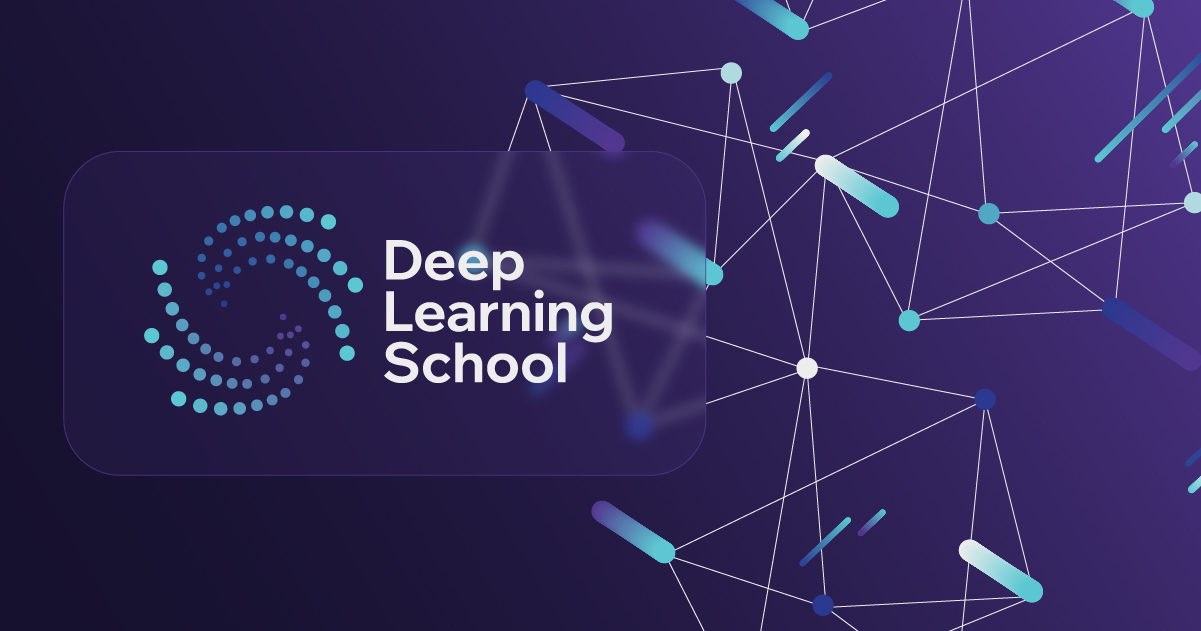

<h3 style="text-align: center;"><b>Школа глубокого обучения ФПМИ МФТИ</b></h3>

<h1 style="text-align: center;"><b>Домашнее задание. Обучение языковой модели с помощью LSTM </b></h1>


В этом задании Вам предстоит обучить языковую модель с помощью рекуррентной нейронной сети. В отличие от семинарского занятия, Вам необходимо будет работать с отдельными словами, а не буквами.


Установим модуль ```datasets```, чтобы нам проще было работать с данными.

In [1]:
!pip install datasets

Импорт необходимых библиотек

In [2]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import numpy as np
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from datasets import load_dataset
from nltk.tokenize import sent_tokenize, word_tokenize, RegexpTokenizer
from sklearn.model_selection import train_test_split
import nltk

import warnings
warnings.filterwarnings('ignore')

from collections import Counter
from typing import List

import seaborn
seaborn.set(palette='summer')

In [3]:
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [4]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

## Подготовка данных

Воспользуемся датасетом imdb. В нем хранятся отзывы о фильмах с сайта imdb. Загрузим данные с помощью функции ```load_dataset```

In [5]:
# Загрузим датасет
dataset = load_dataset('stanfordnlp/imdb')

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

### Препроцессинг данных и создание словаря (1 балл)

Далее вам необходмо самостоятельно произвести препроцессинг данных и получить словарь или же просто ```set``` строк. Что необходимо сделать:

1. Разделить отдельные тренировочные примеры на отдельные предложения с помощью функции ```sent_tokenize``` из бибилиотеки ```nltk```. Каждое отдельное предложение будет одним тренировочным примером.
2. Оставить только те предложения, в которых меньше ```word_threshold``` слов.
3. Посчитать частоту вхождения каждого слова в оставшихся предложениях. Для деления предлоения на отдельные слова удобно использовать функцию ```word_tokenize```.
4. Создать объект ```vocab``` класса ```set```, положить в него служебные токены '\<unk\>', '\<bos\>', '\<eos\>', '\<pad\>' и vocab_size самых частовстречающихся слов.   

Используем RegexpTokenizer чтобы удалить знаки препинания

In [6]:
tokenizer = RegexpTokenizer(r'\w+')

In [7]:
sentences = []
word_threshold = 32

progress_bar = tqdm(desc='create corpus', total=len(dataset['train']['text']), unit='step', leave=True)
for example in dataset['train']['text']:
    sentences += [sentence for sentence in sent_tokenize(example) if len(tokenizer.tokenize(sentence)) < word_threshold]

    progress_bar.set_postfix(len=len(sentences), refresh=False)
    progress_bar.update(1)

progress_bar.close()
# Получить отдельные предложения и поместить их в sentences

create corpus:   0%|          | 0/25000 [00:00<?, ?step/s]

In [8]:
print("Всего предложений:", len(sentences))

Всего предложений: 216118


Посчитаем для каждого слова его встречаемость.

In [9]:
words = Counter()

progress_bar = tqdm(desc='create words counter', total=len(sentences), unit='step', leave=True)
for index, sentence in enumerate(sentences):
    for word in tokenizer.tokenize(sentence):
        words[word] += 1

    if index % 1000 == 0:
        progress_bar.set_postfix(len=len(words), most_common=words.most_common(1)[0], refresh=False)
        progress_bar.update(index - progress_bar.n + 1)

progress_bar.set_postfix(len=len(words), most_common=words.most_common(1)[0], refresh=False)
progress_bar.update(len(sentences) - progress_bar.n)
progress_bar.close()

create words counter:   0%|          | 0/216118 [00:00<?, ?step/s]

Добавим в словарь ```vocab_size``` самых встречающихся слов.

In [10]:
vocab_size = 40000

vocab = set([word[0] for word in words.most_common(vocab_size)])
for special_elem in ['<unk>', '<bos>', '<eos>', '<pad>']:
    vocab.add(special_elem)

In [11]:
assert '<unk>' in vocab
assert '<bos>' in vocab
assert '<eos>' in vocab
assert '<pad>' in vocab
assert len(vocab) == vocab_size + 4

In [12]:
print("Всего слов в словаре:", len(vocab))

Всего слов в словаре: 40004


### Подготовка датасета (1 балл)

Далее, как и в семинарском занятии, подготовим датасеты и даталоадеры.

В классе ```WordDataset``` вам необходимо реализовать метод ```__getitem__```, который будет возвращать сэмпл данных по входному idx, то есть список целых чисел (индексов слов).

Внутри этого метода необходимо добавить служебные токены начала и конца последовательности, а также токенизировать соответствующее предложение с помощью ```word_tokenize``` и сопоставить ему индексы из ```word2ind```.

In [13]:
word2ind = {char: i for i, char in enumerate(vocab)}
ind2word = {i: char for char, i in word2ind.items()}

In [14]:
class WordDataset:
    def __init__(self, sentences):
        self.data = sentences
        self.unk_id = word2ind['<unk>']
        self.bos_id = word2ind['<bos>']
        self.eos_id = word2ind['<eos>']
        self.pad_id = word2ind['<pad>']

    def __getitem__(self, idx: int) -> List[int]:
        tokenized_sentence = [word2ind.get(word, self.unk_id) for word in tokenizer.tokenize(self.data[idx])]
        tokenized_sentence = [self.bos_id] + tokenized_sentence + [self.eos_id]
        return tokenized_sentence

    def __len__(self) -> int:
        return len(self.data)

In [15]:
def collate_fn_with_padding(
    input_batch: List[List[int]], pad_id=word2ind['<pad>']) -> torch.Tensor:
    seq_lens = [len(x) for x in input_batch]
    max_seq_len = max(seq_lens)

    new_batch = []
    for sequence in input_batch:
        for _ in range(max_seq_len - len(sequence)):
            sequence.append(pad_id)
        new_batch.append(sequence)

    sequences = torch.LongTensor(new_batch).to(device)

    new_batch = {
        'input_ids': sequences[:,:-1],
        'target_ids': sequences[:,1:]
    }

    return new_batch

In [16]:
train_sentences, temp_sentences = train_test_split(sentences, test_size=0.2, random_state=42)
eval_sentences, test_sentences = train_test_split(temp_sentences, test_size=0.5, random_state=42)

train_dataset = WordDataset(train_sentences)
eval_dataset = WordDataset(eval_sentences)
test_dataset = WordDataset(test_sentences)

batch_size = 128

train_dataloader = DataLoader(
    train_dataset, shuffle=True, collate_fn=collate_fn_with_padding, batch_size=batch_size)

eval_dataloader = DataLoader(
    eval_dataset, collate_fn=collate_fn_with_padding, batch_size=batch_size)

test_dataloader = DataLoader(
    test_dataset, collate_fn=collate_fn_with_padding, batch_size=batch_size)

## Обучение и архитектура модели

Вам необходимо на практике проверить, что влияет на качество языковых моделей. В этом задании нужно провести серию экспериментов с различными вариантами языковых моделей и сравнить различия в конечной перплексии на тестовом множестве.

Возмоэные идеи для экспериментов:

* Различные RNN-блоки, например, LSTM или GRU. Также можно добавить сразу несколько RNN блоков друг над другом с помощью аргумента num_layers. Вам поможет официальная документация [здесь](https://pytorch.org/docs/stable/generated/torch.nn.LSTM.html)
* Различные размеры скрытого состояния. Различное количество линейных слоев после RNN-блока. Различные функции активации.
* Добавление нормализаций в виде Dropout, BatchNorm или LayerNorm
* Различные аргументы для оптимизации, например, подбор оптимального learning rate или тип алгоритма оптимизации SGD, Adam, RMSProp и другие
* Любые другие идеи и подходы

После проведения экспериментов необходимо составить таблицу результатов, в которой описан каждый эксперимент и посчитана перплексия на тестовом множестве.

Учтите, что эксперименты, которые различаются, например, только размером скрытого состояния или количеством линейных слоев считаются, как один эксперимент.

Успехов!

### Функция evaluate (1 балл)

Заполните функцию ```evaluate```

Так как в некоторых предложениях есть паддинг, а отдельные примеры могут быть сильно заполнены токеном pad, то считать лосс и перплексию, разделив на весь размер батча будет не корректно, и выдаваемое значение в таком случае будет сильно ниже, в случае если считать с токеном pad. Поэтому я накапливал число значащих токенов и считаю лосс и перплексию относительно них, так как в функцию потерь кросс-энтропию передаётся игнорируемое значение pad

In [17]:
def evaluate(model, criterion, dataloader, epoch) -> float:
    model.eval()
    perplexity = []
    total_loss = 0.0
    cur_elems = 0
    with torch.no_grad():
        progress_bar = tqdm(desc=f'evaluate epoch {epoch + 1}', total=len(dataloader), unit='step', leave=True)

        for batch in dataloader:
            logits = model(batch['input_ids']).flatten(start_dim=0, end_dim=1)
            loss = criterion(logits, batch['target_ids'].flatten())

            not_pad_elems = (batch['target_ids'] != word2ind['<pad>']).sum().item()
            total_loss += loss.item() * not_pad_elems
            cur_elems += not_pad_elems

            progress_bar.set_postfix(mean_loss=total_loss / cur_elems, mean_perplexity=torch.exp(torch.tensor(total_loss / cur_elems)).item(), refresh=False)
            progress_bar.update(1)
    progress_bar.close()

    return total_loss / cur_elems, torch.exp(torch.tensor(total_loss / cur_elems)).item()

### Train loop (1 балл)

Напишите функцию для обучения модели.

In [18]:
def train_epoch_model(model, criterion, optimizer, train_dataloader, epoch):
    total_loss = 0.0
    cur_elems = 0

    model.train()
    progress_bar = tqdm(desc=f'train epoch {epoch + 1}', total=len(train_dataloader), unit='step', leave=True)
    for batch in train_dataloader:
        optimizer.zero_grad()
        outp = model(batch['input_ids']).flatten(start_dim=0, end_dim=1)
        loss = criterion(outp, batch['target_ids'].flatten())
        loss.backward()
        optimizer.step()

        not_pad_elems = (batch['target_ids'] != word2ind['<pad>']).sum().item()
        total_loss += loss.item() * not_pad_elems
        cur_elems += not_pad_elems

        progress_bar.set_postfix(mean_loss=total_loss / cur_elems, mean_perplexity=torch.exp(torch.tensor(total_loss / cur_elems)).item(), refresh=False)
        progress_bar.update(1)

    progress_bar.close()

    return total_loss / cur_elems, torch.exp(torch.tensor(total_loss / cur_elems)).item()

### Первый эксперимент (2 балла)

Определите архитектуру модели и обучите её. Возьмём базовую архитектуру из семинара, только использовав LSTM, и проведём первый эксперимент - hidden_dim=128, 15 эпох

In [19]:
class LanguageModel(nn.Module):
    def __init__(self, hidden_dim: int, vocab_size: int):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, hidden_dim)
        self.rnn = nn.LSTM(hidden_dim, hidden_dim, batch_first=True)
        self.linear = nn.Linear(hidden_dim, hidden_dim)
        self.projection = nn.Linear(hidden_dim, vocab_size)

        self.non_lin = nn.Tanh()
        self.dropout = nn.Dropout(p=0.3)

    def forward(self, input_batch):
        embeddings = self.embedding(input_batch)  # [batch_size, seq_len, hidden_dim]
        output, _ = self.rnn(embeddings)  # [batch_size, seq_len, hidden_dim]
        output = self.dropout(self.linear(self.non_lin(output)))  # [batch_size, seq_len, hidden_dim]
        projection = self.projection(self.non_lin(output))  # [batch_size, seq_len, vocab_size]

        return projection

In [20]:
model1 = LanguageModel(hidden_dim=128, vocab_size=len(vocab)).to(device)
criterion1 = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
optimizer1 = torch.optim.Adam(model1.parameters(), lr=1e-3, weight_decay=1e-4)

In [21]:
num_epoch = 15
train_losses1 = []
val_losses1 = []

train_perplexity1 = []
val_perplexity1 = []

for epoch in range(num_epoch):
    epoch_train_loss, epoch_train_perplexity = train_epoch_model(model1, criterion1, optimizer1, train_dataloader, epoch)
    train_losses1.append(epoch_train_loss)
    train_perplexity1.append(epoch_train_perplexity)
    epoch_val_loss, epoch_val_perplexity = evaluate(model1, criterion1, eval_dataloader, epoch)
    val_losses1.append(epoch_val_loss)
    val_perplexity1.append(epoch_val_perplexity)

train epoch 1:   0%|          | 0/1351 [00:00<?, ?step/s]

evaluate epoch 1:   0%|          | 0/169 [00:00<?, ?step/s]

train epoch 2:   0%|          | 0/1351 [00:00<?, ?step/s]

evaluate epoch 2:   0%|          | 0/169 [00:00<?, ?step/s]

train epoch 3:   0%|          | 0/1351 [00:00<?, ?step/s]

...

evaluate epoch 13:   0%|          | 0/169 [00:00<?, ?step/s]

train epoch 14:   0%|          | 0/1351 [00:00<?, ?step/s]

evaluate epoch 14:   0%|          | 0/169 [00:00<?, ?step/s]

train epoch 15:   0%|          | 0/1351 [00:00<?, ?step/s]

evaluate epoch 15:   0%|          | 0/169 [00:00<?, ?step/s]

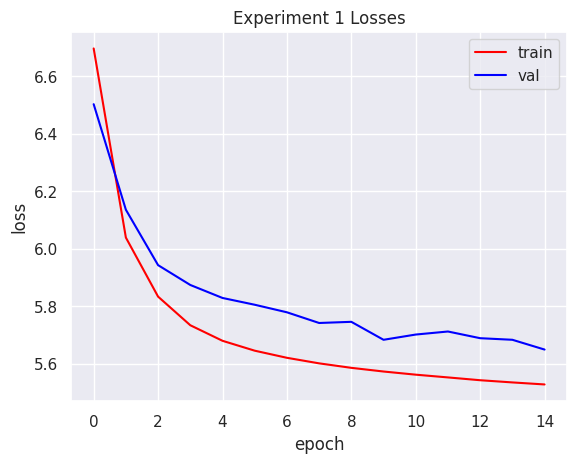

In [22]:
plt.plot(np.arange(len(train_losses1)), train_losses1, label='train', color='r')
plt.plot(np.arange(len(val_losses1)), val_losses1, label='val', color='b')
plt.title('Experiment 1 Losses')
plt.xlabel("epoch")
plt.ylabel('loss')
plt.legend()
plt.show()

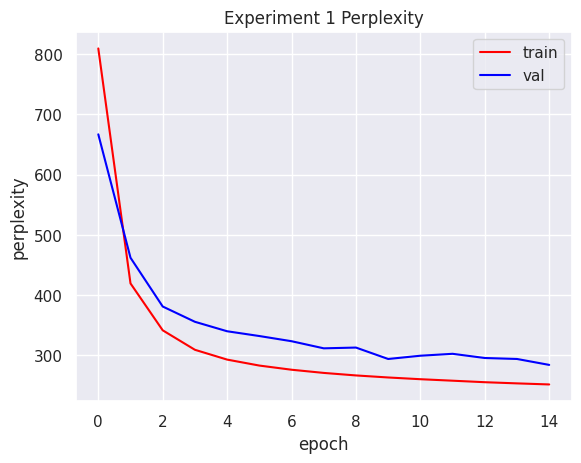

In [23]:
plt.plot(np.arange(len(train_perplexity1)), train_perplexity1, label='train', color='r')
plt.plot(np.arange(len(val_perplexity1)), val_perplexity1, label='val', color='b')
plt.title('Experiment 1 Perplexity')
plt.xlabel("epoch")
plt.ylabel('perplexity')
plt.legend()
plt.show()

Сделаем evaluate на test_dataloader

In [24]:
model1_test_loss, model1_test_perplexity = evaluate(model1, criterion1, test_dataloader, 15)
print(f'Experiment 1_1. loss: {model1_test_loss:.4f}, perplexity: {model1_test_perplexity:.4f}')

evaluate epoch 16:   0%|          | 0/169 [00:00<?, ?step/s]

Experiment 1_1. loss: 5.6495, perplexity: 284.1457


### Второй эксперимент (2 балла)

Добавим num_layers и layer_norm. Проверим с hidden_dim=128 и hidden_dim=256

In [25]:
class LanguageModel2(nn.Module):
    def __init__(self, hidden_dim: int, vocab_size: int):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, hidden_dim)
        self.rnn = nn.LSTM(hidden_dim, hidden_dim, num_layers=2, batch_first=True)
        self.ln_rnn = nn.LayerNorm(hidden_dim)
        self.linear = nn.Linear(hidden_dim, hidden_dim)
        self.ln_linear = nn.LayerNorm(hidden_dim)
        self.projection = nn.Linear(hidden_dim, vocab_size)

        self.non_lin = nn.Tanh()
        self.dropout = nn.Dropout(p=0.3)

    def forward(self, input_batch: torch.Tensor) -> torch.Tensor:
        embeddings = self.embedding(input_batch)
        output, _ = self.rnn(embeddings)
        output = self.ln_rnn(output)
        output = self.dropout(self.linear(self.non_lin(output)))
        output = self.ln_linear(output)
        projection = self.projection(self.non_lin(output))
        return projection

In [26]:
model2 = LanguageModel2(hidden_dim=128, vocab_size=len(vocab)).to(device)
criterion2 = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
optimizer2 = torch.optim.Adam(model2.parameters(), lr=1e-3, weight_decay=1e-4)

In [27]:
num_epoch = 15
train_losses2 = []
val_losses2 = []

train_perplexity2 = []
val_perplexity2 = []

for epoch in range(num_epoch):
    epoch_train_loss, epoch_train_perplexity = train_epoch_model(model2, criterion2, optimizer2, train_dataloader, epoch)
    train_losses2.append(epoch_train_loss)
    train_perplexity2.append(epoch_train_perplexity)
    epoch_val_loss, epoch_val_perplexity = evaluate(model2, criterion2, eval_dataloader, epoch)
    val_losses2.append(epoch_val_loss)
    val_perplexity2.append(epoch_val_perplexity)

train epoch 1:   0%|          | 0/1351 [00:00<?, ?step/s]

evaluate epoch 1:   0%|          | 0/169 [00:00<?, ?step/s]

train epoch 2:   0%|          | 0/1351 [00:00<?, ?step/s]

evaluate epoch 2:   0%|          | 0/169 [00:00<?, ?step/s]

train epoch 3:   0%|          | 0/1351 [00:00<?, ?step/s]

...

evaluate epoch 13:   0%|          | 0/169 [00:00<?, ?step/s]

train epoch 14:   0%|          | 0/1351 [00:00<?, ?step/s]

evaluate epoch 14:   0%|          | 0/169 [00:00<?, ?step/s]

train epoch 15:   0%|          | 0/1351 [00:00<?, ?step/s]

evaluate epoch 15:   0%|          | 0/169 [00:00<?, ?step/s]

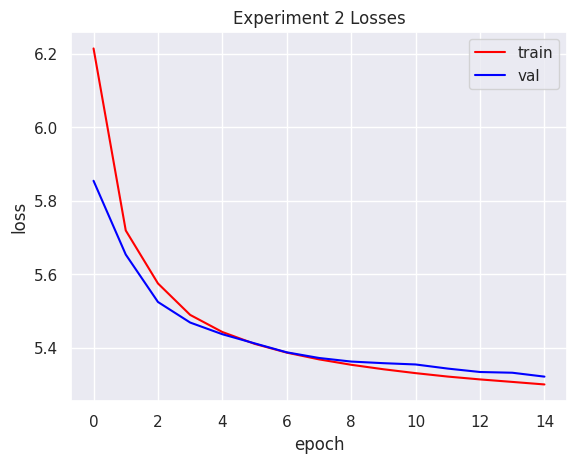

In [28]:
plt.plot(np.arange(len(train_losses2)), train_losses2, label='train', color='r')
plt.plot(np.arange(len(val_losses2)), val_losses2, label='val', color='b')
plt.title('Experiment 2 Losses')
plt.xlabel("epoch")
plt.ylabel('loss')
plt.legend()
plt.show()

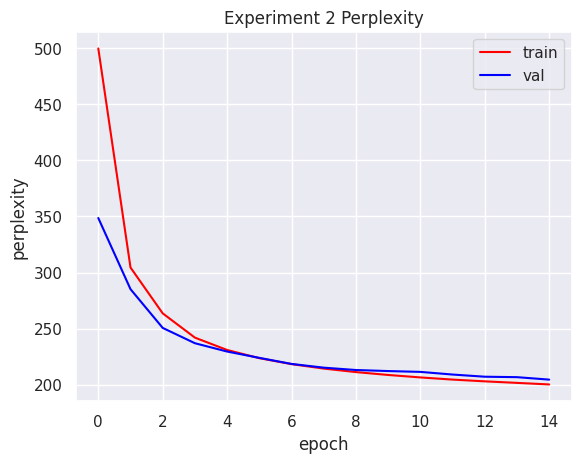

In [29]:
plt.plot(np.arange(len(train_perplexity2)), train_perplexity2, label='train', color='r')
plt.plot(np.arange(len(val_perplexity2)), val_perplexity2, label='val', color='b')
plt.title('Experiment 2 Perplexity')
plt.xlabel("epoch")
plt.ylabel('perplexity')
plt.legend()
plt.show()

Сделаем evaluate на test_dataloader



In [30]:
model2_test_loss, model2_test_perplexity = evaluate(model2, criterion2, test_dataloader, 15)
print(f'Experiment 2. loss: {model2_test_loss:.4f}, perplexity: {model2_test_perplexity:.4f}')

evaluate epoch 16:   0%|          | 0/169 [00:00<?, ?step/s]

Experiment 2. loss: 5.3169, perplexity: 203.7596


Теперь hidden_dim=256. Так как меняем только размер скрытого слоя, то это в рамках эксперимента 2

In [31]:
model2_1 = LanguageModel2(hidden_dim=256, vocab_size=len(vocab)).to(device)
criterion2_1 = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
optimizer2_1 = torch.optim.Adam(model2_1.parameters(), lr=1e-3, weight_decay=1e-4)

In [32]:
num_epoch = 15
train_losses2_1 = []
val_losses2_1 = []

train_perplexity2_1 = []
val_perplexity2_1 = []

for epoch in range(num_epoch):
    epoch_train_loss, epoch_train_perplexity = train_epoch_model(model2_1, criterion2_1, optimizer2_1, train_dataloader, epoch)
    train_losses2_1.append(epoch_train_loss)
    train_perplexity2_1.append(epoch_train_perplexity)
    epoch_val_loss, epoch_val_perplexity = evaluate(model2_1, criterion2_1, eval_dataloader, epoch)
    val_losses2_1.append(epoch_val_loss)
    val_perplexity2_1.append(epoch_val_perplexity)

train epoch 1:   0%|          | 0/1351 [00:00<?, ?step/s]

evaluate epoch 1:   0%|          | 0/169 [00:00<?, ?step/s]

train epoch 2:   0%|          | 0/1351 [00:00<?, ?step/s]

evaluate epoch 2:   0%|          | 0/169 [00:00<?, ?step/s]

train epoch 3:   0%|          | 0/1351 [00:00<?, ?step/s]

...

evaluate epoch 13:   0%|          | 0/169 [00:00<?, ?step/s]

train epoch 14:   0%|          | 0/1351 [00:00<?, ?step/s]

evaluate epoch 14:   0%|          | 0/169 [00:00<?, ?step/s]

train epoch 15:   0%|          | 0/1351 [00:00<?, ?step/s]

evaluate epoch 15:   0%|          | 0/169 [00:00<?, ?step/s]

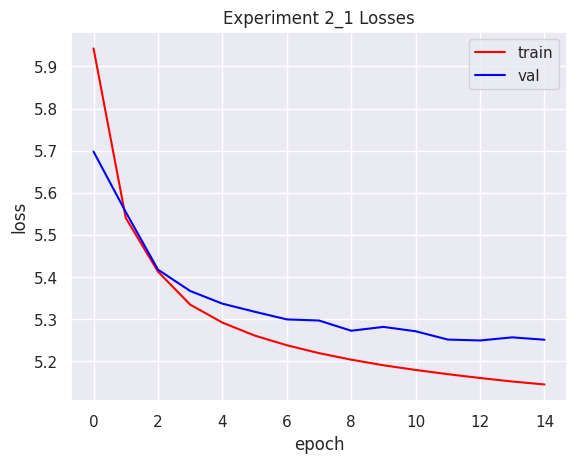

In [33]:
plt.plot(np.arange(len(train_losses2_1)), train_losses2_1, label='train', color='r')
plt.plot(np.arange(len(val_losses2_1)), val_losses2_1, label='val', color='b')
plt.title('Experiment 2_1 Losses')
plt.xlabel("epoch")
plt.ylabel('loss')
plt.legend()
plt.show()

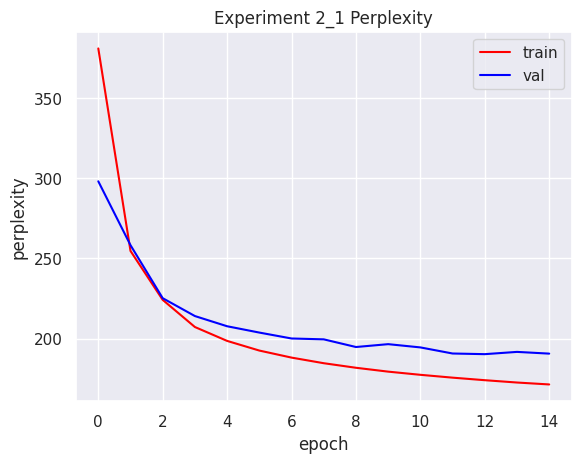

In [34]:
plt.plot(np.arange(len(train_perplexity2_1)), train_perplexity2_1, label='train', color='r')
plt.plot(np.arange(len(val_perplexity2_1)), val_perplexity2_1, label='val', color='b')
plt.title('Experiment 2_1 Perplexity')
plt.xlabel("epoch")
plt.ylabel('perplexity')
plt.legend()
plt.show()

Сделаем evaluate на test_dataloader

In [35]:
model2_1_test_loss, model2_1_test_perplexity = evaluate(model2_1, criterion2_1, test_dataloader, 15)
print(f'Experiment 2_1. loss: {model2_1_test_loss:.4f}, perplexity: {model2_1_test_perplexity:.4f}')

evaluate epoch 16:   0%|          | 0/169 [00:00<?, ?step/s]

Experiment 2_1. loss: 5.2453, perplexity: 189.6788


### Третий эксперимент

Используем GRU.

In [36]:
class LanguageModel3(nn.Module):
    def __init__(self, hidden_dim: int, vocab_size: int):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, hidden_dim)
        self.rnn = nn.GRU(hidden_dim, hidden_dim, num_layers=2, batch_first=True)
        self.ln_rnn = nn.LayerNorm(hidden_dim)
        self.linear = nn.Linear(hidden_dim, hidden_dim)
        self.ln_linear = nn.LayerNorm(hidden_dim)
        self.projection = nn.Linear(hidden_dim, vocab_size)

        self.non_lin = nn.Tanh()
        self.dropout = nn.Dropout(p=0.3)

    def forward(self, input_batch: torch.Tensor) -> torch.Tensor:
        embeddings = self.embedding(input_batch)
        output, _ = self.rnn(embeddings)
        output = self.ln_rnn(output)
        output = self.dropout(self.linear(self.non_lin(output)))
        output = self.ln_linear(output)
        projection = self.projection(self.non_lin(output))
        return projection

In [37]:
model3 = LanguageModel3(hidden_dim=256, vocab_size=len(vocab)).to(device)
criterion3 = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
optimizer3 = torch.optim.Adam(model3.parameters(), lr=1e-3, weight_decay=1e-4)

In [38]:
num_epoch = 15
train_losses3 = []
val_losses3 = []

train_perplexity3 = []
val_perplexity3 = []

for epoch in range(num_epoch):
    epoch_train_loss, epoch_train_perplexity = train_epoch_model(model3, criterion3, optimizer3, train_dataloader, epoch)
    train_losses3.append(epoch_train_loss)
    train_perplexity3.append(epoch_train_perplexity)
    epoch_val_loss, epoch_val_perplexity = evaluate(model3, criterion3, eval_dataloader, epoch)
    val_losses3.append(epoch_val_loss)
    val_perplexity3.append(epoch_val_perplexity)

train epoch 1:   0%|          | 0/1351 [00:00<?, ?step/s]

evaluate epoch 1:   0%|          | 0/169 [00:00<?, ?step/s]

train epoch 2:   0%|          | 0/1351 [00:00<?, ?step/s]

evaluate epoch 2:   0%|          | 0/169 [00:00<?, ?step/s]

train epoch 3:   0%|          | 0/1351 [00:00<?, ?step/s]

...

evaluate epoch 13:   0%|          | 0/169 [00:00<?, ?step/s]

train epoch 14:   0%|          | 0/1351 [00:00<?, ?step/s]

evaluate epoch 14:   0%|          | 0/169 [00:00<?, ?step/s]

train epoch 15:   0%|          | 0/1351 [00:00<?, ?step/s]

evaluate epoch 15:   0%|          | 0/169 [00:00<?, ?step/s]

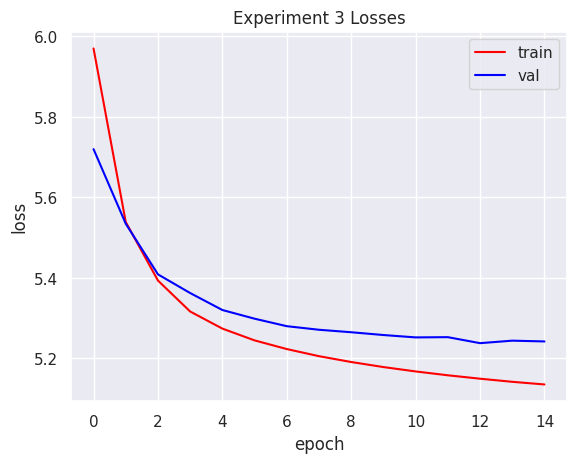

In [55]:
plt.plot(np.arange(len(train_losses3)), train_losses3, label='train', color='r')
plt.plot(np.arange(len(val_losses3)), val_losses3, label='val', color='b')
plt.title('Experiment 3 Losses')
plt.xlabel("epoch")
plt.ylabel('loss')
plt.legend()
plt.show()

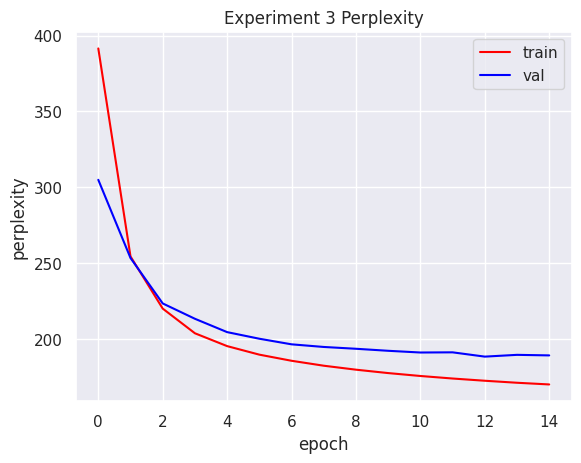

In [58]:
plt.plot(np.arange(len(train_perplexity3)), train_perplexity3, label='train', color='r')
plt.plot(np.arange(len(val_perplexity3)), val_perplexity3, label='val', color='b')
plt.title('Experiment 3 Perplexity')
plt.xlabel("epoch")
plt.ylabel('perplexity')
plt.legend()
plt.show()

Сделаем evaluate на test_dataloader

In [60]:
model3_test_loss, model3_test_perplexity = evaluate(model3, criterion3, test_dataloader, 15)
print(f'Experiment 3. loss: {model3_test_loss:.4f}, perplexity: {model3_test_perplexity:.4f}')

evaluate epoch 16:   0%|          | 0/169 [00:00<?, ?step/s]

Experiment 3. loss: 5.2377, perplexity: 188.2348


In [66]:
def generate_sequence(model, starting_seq: str, max_seq_len: int = 128) -> str:
    device = 'cpu'
    model = model.to(device)
    input_ids = [word2ind['<bos>']] + [
        word2ind.get(word, word2ind['<unk>']) for word in starting_seq.split()]
    input_ids = torch.LongTensor(input_ids).to(device)

    model.eval()
    with torch.no_grad():
        for i in range(max_seq_len):
            next_word_distribution = model(input_ids)[-1]
            next_word = next_word_distribution.squeeze().argmax()
            input_ids = torch.cat([input_ids, next_word.unsqueeze(0)])

            if next_word.item() == word2ind['<eos>']:
                break

    sentencies = ' '.join([ind2word[idx.item()] for idx in input_ids if idx not in (word2ind['<eos>'], word2ind['<bos>'], word2ind['<unk>'], word2ind['<pad>'])])

    return sentencies

In [67]:
generate_sequence(model3, starting_seq='this is the best', max_seq_len=16)

'this is the best movie I ve seen in a long time'

Получилось что-то даже осмысленное)

### Отчет (2 балла)

Опишите проведенные эксперименты. Сравните перплексии полученных моделей. Предложите идеи по улучшению качества моделей.

| Номер эксперимента | Описание эксперимента | Loss на test | Перплексия на test | Вывод по построенной модели |
|:---:|:---:|:---:|:---:|:---:|
| Эксперимент 1 | Обучена базовая модель из семинара. <br> Вместо слоя GRU был взят слой LSTM. <br> Обучение на 15 эпохах, hidden_dim=128 | 5.6495 | 284.1457 | Модель, исходя из графиков, обучается стабильно - loss <br> и перплексия падают, что хорошо для базовой модели|
| Эксперимент 2 | Относительно эксперимента 1 добавлено num_layers=2 и layer_norm. <br> Обучение на 15 эпохах, hidden_dim=128 | 5.3169 | 203.7596 | Модель, исходя из графиков, обучается стабильно - loss и перплексия падают. <br> Относительно эксперимента 1 данная модель показала меньший loss и перплексию. <br> Можно сделать вывод, что изменения принесли улучшение качества|
| Эксперимент 2_1 | Модель такая же, что и в эксперименте 2. <br> Обучение на 15 эпохах, только hidden_dim=256 | 5.2453 | 189.6788 | Модель, исходя из графиков, обучается стабильно - loss и перплексия падают. <br> Относительно эксперимента 2 данная модель показала меньший loss и перплексию, <br> но стала обучаться в среднем на 1 минуту больше на одной эпохе <br> Можно сделать вывод, что увеличение hidden_dim принесло улучшение качества|
| Эксперимент 3 | Относительно эксперимента 2_1 тип реккурентного слоя был изменён на GRU. <br> Обучение на 15 эпохах, hidden_dim=256 | 5.2377 | 188.2348 | Модель, исходя из графиков, обучается стабильно - loss и перплексия падают. <br> Относительно эксперимента 2_1 данная модель показала небольшое уменьшение loss <br> и перплексии. Также модель стала обучаться в среднем на 4 секунды меньше на одной эпохе|

 В качестве идей по улучшению можно попробовать обучить большее число эпох или использовать трансформеры